In [14]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [15]:
### Création du dossier figures s'il n'existe pas

In [16]:
Path("figures").mkdir(exist_ok=True)
print("Étape 1 validée : Bibliothèques importées et dossier 'figures' prêt.")

Étape 1 validée : Bibliothèques importées et dossier 'figures' prêt.


In [20]:
# 1. Chargement des données
df = pd.read_csv("data/logs_reseau.csv")

# 2. Nettoyage des données
# a. Supprimer les doublons exacts
df = df.drop_duplicates()

# b. Mettre le protocole en MAJUSCULES
if "protocol" in df.columns:
  df["protocol"] = df["protocol"].astype(str).str.upper()

# c. Remplacer les bytes_sent manquants par la médiane
if "bytes_sent" in df.columns:
  mediane_bytes = df["bytes_sent"].median()
  df["bytes_sent"] = df["bytes_sent"].fillna(mediane_bytes)

print(f"Étape 2 validée : Données nettoyées. Lignes restantes : {len(df)}")

Étape 2 validée : Données nettoyées. Lignes restantes : 5440


In [21]:
# 3. Calculs des résultats demandés
top_port = int(df["dst_port"].mode()[0])

total_connexions = len(df)
if total_connexions > 0:
  nb_deny = len(df[df["action"].str.upper() == "DENY"])
  taux_deny_pct = round((nb_deny / total_connexions) * 100, 2)
else:
  taux_deny_pct = 0.0

if "src_ip" in df.columns and "dst_port" in df.columns:
  ip_scanner = (
      df.groupby("src_ip")["dst_port"].nunique().idxmax()
      if not df.empty
      else ""
  )
else:
  ip_scanner = ""

if "src_ip" in df.columns and "bytes_sent" in df.columns:
  ip_exfiltration = (
      df.groupby("src_ip")["bytes_sent"].sum().idxmax() if not df.empty else ""
  )
else:
  ip_exfiltration = ""

# Dictionnaire des résultats
resultats = {
    "nb_lignes_apres_nettoyage": len(df),
    "top_port": top_port,
    "taux_deny_pct": taux_deny_pct,
    "ip_scanner": ip_scanner,
    "ip_exfiltration": ip_exfiltration,
}

# Sauvegarde dans resultats.json
with open("resultats.json", "w", encoding="utf-8") as f:
  json.dump(resultats, f, indent=4)

print("Étape 3 validée : Résultats calculés et enregistrés dans 'resultats.json'")
print(resultats)

Étape 3 validée : Résultats calculés et enregistrés dans 'resultats.json'
{'nb_lignes_apres_nettoyage': 5440, 'top_port': 443, 'taux_deny_pct': 13.57, 'ip_scanner': '192.168.1.99', 'ip_exfiltration': '192.168.1.11'}


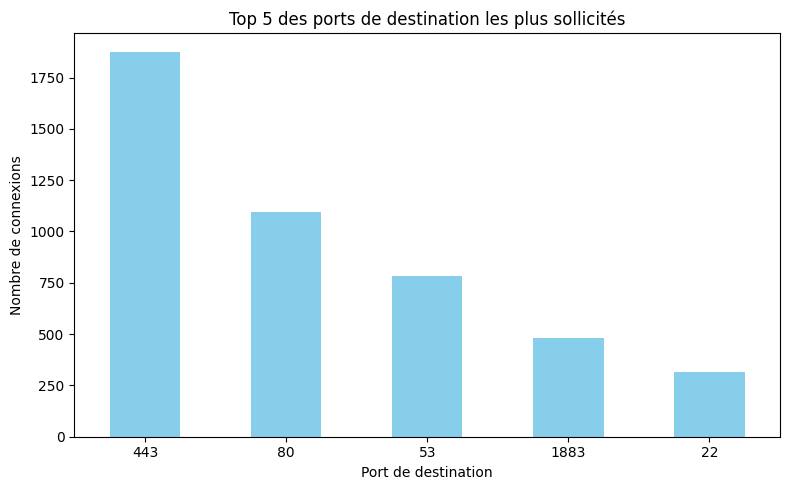

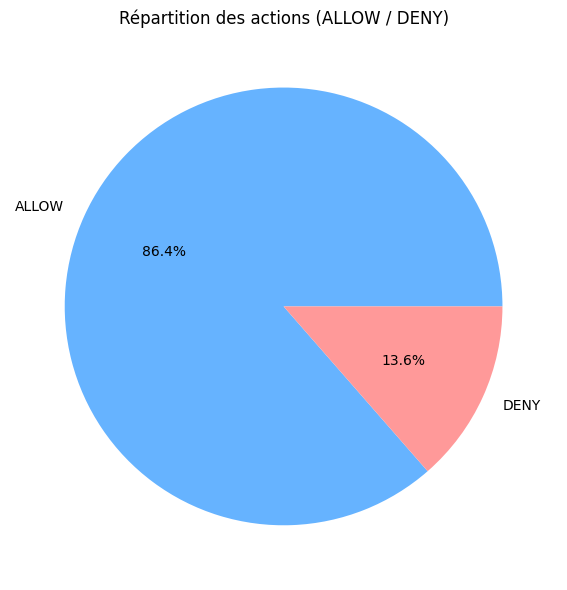

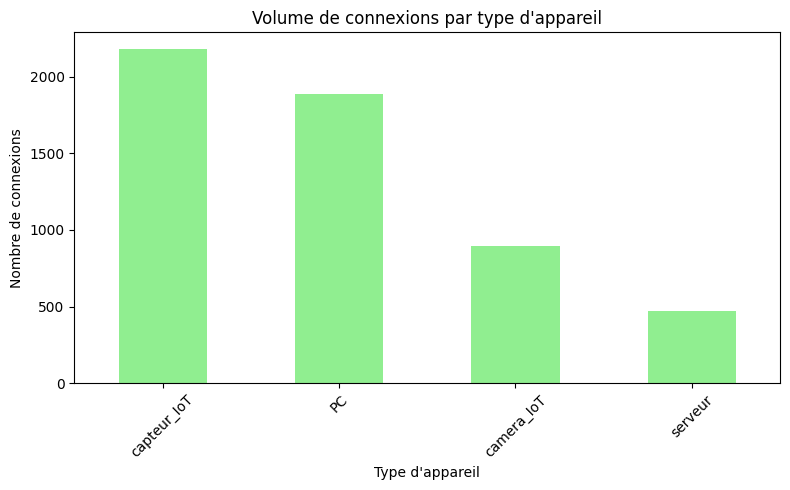

Étape 4 validée : Toutes les figures sont générées et affichées !


In [22]:
# Figure 1 : Top 5 des ports de destination
plt.figure(figsize=(8, 5))
top_ports_series = df["dst_port"].value_counts().head(5)
top_ports_series.plot(kind="bar", color="skyblue")
plt.title("Top 5 des ports de destination les plus sollicités")
plt.xlabel("Port de destination")
plt.ylabel("Nombre de connexions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/top_ports.png")
plt.show()  # Affiche le graphique dans le notebook
plt.close()

# Figure 2 : Répartition des actions (ALLOW / DENY)
plt.figure(figsize=(6, 6))
action_counts = df["action"].str.upper().value_counts()
action_counts.plot(
    kind="pie", autopct="%1.1f%%", colors=["#66b3ff", "#ff9999"]
)
plt.title("Répartition des actions (ALLOW / DENY)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/repartition_actions.png")
plt.show()
plt.close()

# Figure 3 : Volume de connexions par type d'appareil
plt.figure(figsize=(8, 5))
if "device_type" in df.columns:
  df["device_type"].value_counts().plot(kind="bar", color="lightgreen")
  plt.title("Volume de connexions par type d'appareil")
  plt.xlabel("Type d'appareil")
  plt.ylabel("Nombre de connexions")
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.savefig("figures/connexions_temps.png")
  plt.show()
  plt.close()

print("Étape 4 validée : Toutes les figures sont générées et affichées !")